# Thí nghiệm 1-2: Ảnh hưởng của toán tử và tham số trong Genetic Algorithm

**Đề tài 6, nhóm 9.** Trưởng nhóm Trương Thành Đạt phụ trách GA, ba thành viên còn lại phụ trách EHO. Notebook này chỉ thực nghiệm Genetic Algorithm (thuật toán di truyền). EHO chưa được triển khai; GUI GA đã có nhưng không tham gia đo thời gian ở đây.

**Cách chạy:** từ root dự án cài `python -m pip install -r requirements.txt`, mở Jupyter hoặc VS Code, chọn interpreter `.venv`, rồi **Restart Kernel & Run All**. Có thể mở từ root hoặc thư mục `Experiment/`. Nếu import lỗi, kiểm tra kernel và cài package bằng interpreter đó; không chỉnh `sys.path`.

Giữ `MODE = 'QUICK'` cho lần đầu. Chế độ này sử dụng năm seed `[11, 23, 37, 53, 71]`; seed là số khởi tạo bộ sinh ngẫu nhiên, giúp chạy lại cùng một phép thử. Đổi sang `FULL` rồi khởi động lại kernel để dùng 25 seed `[101, ..., 125]`. Đây là hai tập khác nhau, không gộp chúng thành một mẫu. Mọi lần chạy có số thế hệ hữu hạn và các nhóm so sánh cùng số phép tính còn có giới hạn evaluations. Notebook không tự chạy lại để tìm một kết quả mong muốn và không xuất file kết quả vào repository.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import Counter
from math import fsum, isclose
import platform
import statistics
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython import get_ipython
from IPython.display import display, Markdown

from ga_eho_tsp import __version__
from ga_eho_tsp.algorithms.ga import solve
from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import GAConfig
from ga_eho_tsp.domain.objective import validate_route

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 95, 'font.size': 10})
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'pyproject.toml').is_file() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở notebook từ root dự án hoặc Experiment/ sau khi cài package.')

MODE = 'QUICK'  # Đổi thành 'FULL', sau đó Restart Kernel & Run All.
if MODE not in {'QUICK', 'FULL'}:
    raise ValueError('MODE chỉ nhận QUICK hoặc FULL.')
SEEDS = [11, 23, 37, 53, 71] if MODE == 'QUICK' else list(range(101, 126))
MAX_RUNS = 200 if MODE == 'QUICK' else 1000
TOTAL_SOLVER_LIMIT = 180.0 if MODE == 'QUICK' else 900.0
RUN_COUNT, SOLVER_SECONDS = 0, 0.0
SESSION_START = perf_counter()
print(f'Python {platform.python_version()} | GA {__version__} | chế độ {MODE}')
print(f'Seed: {SEEDS}; tối đa {MAX_RUNS} lần gọi GA; tổng thời gian solver tối đa {TOTAL_SOLVER_LIMIT:g} giây.')

Python 3.11.9 | GA 0.2.0 | chế độ QUICK
Seed: [11, 23, 37, 53, 71]; tối đa 200 lần gọi GA; tổng thời gian solver tối đa 180 giây.


### Quy ước đọc số liệu và các hàm hỗ trợ

Một **lần đánh giá lời giải (evaluation)** là một lần chương trình tính độ dài toàn bộ tuyến đường. Hai cá thể tốt nhất được giữ lại qua thế hệ không cần tính lại chi phí. Khi tắt tìm kiếm cục bộ và hoàn tất G thế hệ, số evaluations bằng `P + G × (P − 2)`, với P là kích thước quần thể và hai cá thể được giữ lại. Vì vậy, cùng số thế hệ chưa có nghĩa là cùng khối lượng tính toán.

**Độ lệch chuẩn** được tính từ các kết quả của tất cả seed, với mẫu số là số lần chạy trừ một. Nó cho biết kết quả phân tán nhiều hay ít quanh trung bình; giá trị nhỏ không tự chứng minh lời giải gần tối ưu. Thời gian đo trong solver, không bao gồm đọc dữ liệu hoặc vẽ hình, và vẫn phụ thuộc máy đang sử dụng.

Những hàm ngắn dưới đây chỉ kiểm tra, tổng hợp và vẽ kết quả; chúng không cài đặt lại GA. Mỗi tour được kiểm tra là hoán vị đủ thành phố, bắt đầu ở0, và tính lại chi phí trực tiếp từ ma trận, bao gồm cạnh quay về đầu. Nếu một lần chạy lỗi, notebook dừng và nêu lỗi, không bỏ kết quả đó để tính trung bình. Nếu dừng sớm vì thời gian hoặc trì trệ, kết quả hợp lệ vẫn được giữ và trạng thái được liệt kê trong bảng.

Trong bảng cấu hình, cột **Thế hệ G/M** lần lượt là `generations` và `max_iterations`; số vòng tối đa thực sự là giá trị nhỏ hơn trong hai số. Trong bảng kết quả, **Đánh giá min–max** và **Thế hệ TB** là số đã thực hiện, không phải giới hạn đã nhập. Mọi đường hội tụ dùng lời giải tốt nhất từ đầu đến thời điểm đó (`best_so_far`), nên không tăng khi thuật toán tìm được lời giải mới.

Các mã trong cột lý do dừng có ý nghĩa như sau: `MAX_ITERATIONS` là hết số thế hệ cho phép; `MAX_EVALUATIONS` là đã dùng hết số lần đánh giá; `TIME_LIMIT` là hết thời gian được cấp; `STAGNATION` là đạt số thế hệ không cải thiện đã đặt; `CANCELLED` là có yêu cầu hủy. Chúng mô tả cách lần chạy kết thúc, không xác nhận đã tìm được nghiệm tối ưu.

In [2]:
def show_table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))


def checked_solve(problem, config):
    global RUN_COUNT, SOLVER_SECONDS
    if RUN_COUNT >= MAX_RUNS or SOLVER_SECONDS >= TOTAL_SOLVER_LIMIT:
        raise RuntimeError('Vượt giới hạn notebook; batch chưa hoàn tất, không được báo thành công.')
    result = solve(problem, config)
    RUN_COUNT += 1
    SOLVER_SECONDS += result.elapsed_seconds
    validate_route(result.best_route, problem.dimension)
    route = result.best_route
    cost = fsum(problem.distance_matrix[route[i]][route[(i + 1) % len(route)]]
                for i in range(len(route)))
    assert result.is_valid and isclose(cost, result.best_distance, abs_tol=1e-9, rel_tol=1e-12)
    assert result.config_snapshot == asdict(config)
    assert result.iterations_completed <= min(config.generations, config.max_iterations)
    if config.max_evaluations is not None:
        assert result.evaluations <= config.max_evaluations
    assert result.history[0].iteration == 0
    assert result.history[0].evaluations == config.population_size
    assert result.history[-1].evaluations == result.evaluations
    assert result.history[-1].best_so_far == result.best_distance
    assert all(b.best_so_far <= a.best_so_far and b.evaluations >= a.evaluations
               for a, b in zip(result.history, result.history[1:]))
    assert result.metadata['local_search_full_evaluations'] <= result.evaluations
    if not config.local_search_enabled and result.stopping_reason == 'MAX_ITERATIONS':
        assert result.evaluations == config.population_size + result.iterations_completed * (
            config.population_size - config.elite_count)
    return result


def summarize(runs):
    assert len(runs) == len(SEEDS) and [r.seed for r in runs] == SEEDS
    distances = [r.best_distance for r in runs]
    return dict(mean=statistics.mean(distances), std=statistics.stdev(distances),
                best=min(distances), worst=max(distances), median=statistics.median(distances),
                eval_min=min(r.evaluations for r in runs), eval_max=max(r.evaluations for r in runs),
                eval_mean=statistics.mean(r.evaluations for r in runs),
                generations=statistics.mean(r.iterations_completed for r in runs),
                seconds=statistics.mean(r.elapsed_seconds for r in runs),
                initial_mean=statistics.mean(r.history[0].best_so_far for r in runs),
                local_calls=statistics.mean(r.metadata['local_search_full_evaluations'] for r in runs),
                reasons=dict(Counter(r.stopping_reason for r in runs)))


def run_group(problem, configs):
    show_table(['Cấu hình', 'Quần thể P', 'Thế hệ G/M', 'Tỷ lệ đột biến', 'Giới hạn đánh giá'],
               [[name, c.population_size, f'{c.generations}/{c.max_iterations}', c.mutation_rate,
                 c.max_evaluations if c.max_evaluations is not None else 'Không đặt thêm']
                for name, c in configs.items()])
    return {name: [checked_solve(problem, replace(c, seed=seed)) for seed in SEEDS]
            for name, c in configs.items()}


def present_group(groups, title):
    summary = {name: summarize(runs) for name, runs in groups.items()}
    show_table(['Cấu hình', 'Tốt nhất', 'Trung bình', 'Độ lệch chuẩn', 'Đánh giá min–max',
                'Thế hệ TB', 'Thời gian TB (s)', 'Lý do dừng (số lần)'],
               [[name, f"{s['best']:g}", f"{s['mean']:.2f}", f"{s['std']:.2f}",
                 f"{s['eval_min']}–{s['eval_max']}", f"{s['generations']:.1f}",
                 f"{s['seconds']:.4f}", ', '.join(f'{k}: {v}' for k, v in s['reasons'].items())]
                for name, s in summary.items()])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
    names = list(summary)
    axes[0].barh(names, [summary[n]['mean'] for n in names],
                 xerr=[summary[n]['std'] for n in names], capsize=3, color='#42849c')
    axes[0].set(xlabel='Độ dài trung bình (đơn vị ma trận)', ylabel='Cấu hình', title='Trung bình và độ lệch chuẩn')
    for name, runs in groups.items():
        history = runs[0].history  # Seed đầu cố định, không chọn lời giải đẹp nhất.
        axes[1].step([s.evaluations for s in history], [s.best_so_far for s in history],
                     where='post', label=name)
    axes[1].set(xlabel='Số lần đánh giá lời giải', ylabel='Độ dài tốt nhất đã tìm được',
                title=f'Quá trình cải thiện, seed {SEEDS[0]}')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=.2)
    fig.suptitle(title, fontsize=12)
    plt.show()
    plt.close(fig)
    return summary


def discuss(summary, context):
    reference = next(iter(summary))
    base = summary[reference]
    observations = []
    for name, row in summary.items():
        if name != reference:
            difference = row['mean'] - base['mean']
            observations.append(f"**{name}** có trung bình {row['mean']:.2f}, chênh {difference:+.2f} "
                                f"đơn vị so với **{reference}**; số đánh giá trung bình là "
                                f"{row['eval_mean']:.0f} thay vì {base['eval_mean']:.0f}.")
    minimum = min(s['mean'] for s in summary.values())
    winners = ', '.join(name for name, s in summary.items() if s['mean'] == minimum)
    display(Markdown('**Nhận xét từ dữ liệu vừa chạy.** ' + ' '.join(observations) + '\n\n'
        f'Trong nhóm này, {winners} có trung bình nhỏ nhất ({minimum:.2f}). ' + context +
        f' Kết luận chỉ áp dụng cho dữ liệu, tham số và {len(SEEDS)} seed đã công bố; '
        'chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.'))


def numeric_signature(result):
    return (result.best_route, result.best_distance, result.evaluations, result.iterations_completed,
            result.stopping_reason, result.config_snapshot,
            tuple((s.iteration, s.best_current, s.best_so_far, s.mean_fitness,
                   s.evaluations, s.population_diversity) for s in result.history))

## Phần 1. Các toán tử ảnh hưởng thế nào đến quá trình tìm kiếm?

GA duy trì một quần thể gồm nhiều lời giải, chọn bố mẹ, tạo cá thể con rồi đột biến để tìm các tuyến khác. Vì vậy, ngoài số cá thể và số thế hệ, cách chọn và biến đổi lời giải cũng có thể ảnh hưởng đến kết quả. Chúng tôi dùng bài toán 15 thành phố, trong đó phần tử ở hàng i, cột j của ma trận là chi phí di chuyển giữa hai thành phố. Mục tiêu là đi qua mỗi thành phố đúng một lần rồi quay về điểm xuất phát. Chi phí không mặc định là kilômét và 1194 trong tên file chưa được coi là nghiệm tối ưu đã chứng minh.

Trong cấu hình cơ bản, quần thể được tạo ngẫu nhiên. **Tournament Selection (chọn lọc thi đấu)** lấy ba ứng viên rồi chọn ứng viên có tuyến ngắn nhất làm bố mẹ. **Order Crossover, OX (lai ghép theo thứ tự)** giữ một đoạn của bố mẹ và điền các thành phố còn thiếu theo thứ tự từ bố mẹ còn lại. **Inversion Mutation (đột biến đảo đoạn)** đảo thứ tự một đoạn của tour, với xác suất 15% cho cả cá thể; phép lai có xác suất 90%. **Elitism (giữ lại cá thể tốt)** chuyển nguyên hai cá thể tốt nhất sang thế hệ mới, không phải một phương pháp chọn bố mẹ thay cho Tournament.

Mỗi nhóm dưới chỉ thay một thành phần, giúp chúng ta đọc tác động của nó rõ hơn so với việc đổi đồng thời cả ba toán tử. Các nhóm dùng cùng giới hạn 2000 evaluations ở QUICK và 6000 ở FULL; cả hai giới hạn thế hệ đều đặt 2000 để không dừng nhầm ở250. Cấu hình thí nghiệm dùng P40 để chạy gọn, khác mặc định P80 của ứng dụng; các giá trị còn lại được lấy từ GAConfig.

In [3]:
problem = load_matrix(ROOT/'data/15Cities-1194.txt')
EVALUATIONS = 2000 if MODE == 'QUICK' else 6000
BASE = replace(GAConfig(), population_size=40, generations=2000,
               max_iterations=2000, max_evaluations=EVALUATIONS, time_limit_seconds=10.0)
print(f'Dữ liệu {problem.name}: {problem.dimension} thành phố; nguồn: {problem.source}')

Dữ liệu 15Cities-1194: 15 thành phố; nguồn: D:\ga-eho-tsp\data\15Cities-1194.txt


### Trường hợp 1 - Cấu hình cơ bản

Chúng tôi bắt đầu với cấu hình vừa mô tả để có mốc đối chiếu. Một đường hội tụ sớm nằm ngang chỉ cho biết run đó chưa tìm thêm tour tốt hơn; nó không chứng minh đã đạt tối ưu.


Bảng đầu công bố tham số trước khi chạy; bảng tiếp theo tổng hợp đủ tất cả seed. Ở hình bên trái, thanh ngắn hơn tương ứng với độ dài trung bình nhỏ hơn; đoạn ngang ở đầu thanh biểu diễn một độ lệch chuẩn, không phải khoảng tin cậy. Ở hình bên phải, trục ngang là số lần đánh giá lời giải, trục dọc là độ dài tốt nhất đã tìm được; đường thấp hơn là tốt hơn tại cùng số phép đánh giá. Mỗi đường dùng seed đầu tiên đã công bố để minh họa, không phải đường trung bình của các seed và không kéo dài sau khi run dừng.

In [4]:
configs = {'Cơ bản': BASE}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Cơ bản | 40 | 2000/2000 | 0.15 | 2000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Cơ bản | 1194 | 1235.00 | 43.86 | 2000–2000 | 51.0 | 0.0251 | MAX_EVALUATIONS: 5 |

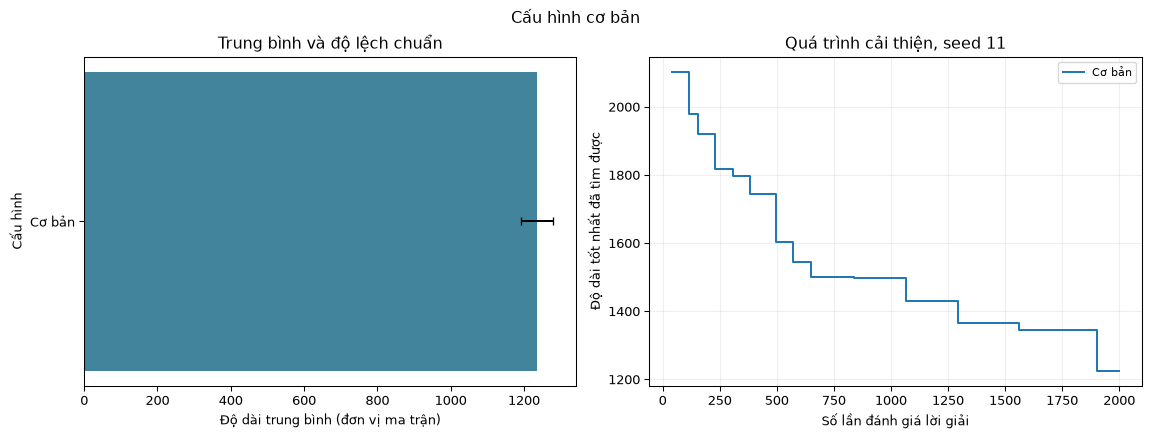

In [5]:
basic_runs = run_group(problem, configs)
basic_runs_summary = present_group(basic_runs, 'Cấu hình cơ bản')

In [6]:
discuss(basic_runs_summary, 'Đường giảm thể hiện những lần cải thiện thực sự; đoạn nằm ngang không phải bằng chứng tối ưu.')

**Nhận xét từ dữ liệu vừa chạy.** 

Trong nhóm này, Cơ bản có trung bình nhỏ nhất (1235.00). Đường giảm thể hiện những lần cải thiện thực sự; đoạn nằm ngang không phải bằng chứng tối ưu. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Trường hợp 2 - Thay phương pháp chọn bố mẹ

**Rank Selection (chọn lọc theo thứ hạng)** gán cơ hội chọn theo vị trí xếp hạng, trong khi **Roulette Wheel Selection (chọn lọc bánh xe roulette)** chọn ngẫu nhiên có trọng số ưu tiên tuyến ngắn. Giữ OX và Inversion giúp khảo sát lựa chọn bố mẹ mà không trộn thêm thay đổi ở con.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [7]:
configs = {'Tournament': BASE, 'Rank': replace(BASE, selection_method='rank'),
           'Roulette': replace(BASE, selection_method='roulette_wheel')}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Tournament | 40 | 2000/2000 | 0.15 | 2000 |
| Rank | 40 | 2000/2000 | 0.15 | 2000 |
| Roulette | 40 | 2000/2000 | 0.15 | 2000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Tournament | 1194 | 1235.00 | 43.86 | 2000–2000 | 51.0 | 0.0256 | MAX_EVALUATIONS: 5 |
| Rank | 1324 | 1413.60 | 81.79 | 2000–2000 | 51.0 | 0.0225 | MAX_EVALUATIONS: 5 |
| Roulette | 1241 | 1400.80 | 158.48 | 2000–2000 | 51.0 | 0.0227 | MAX_EVALUATIONS: 5 |

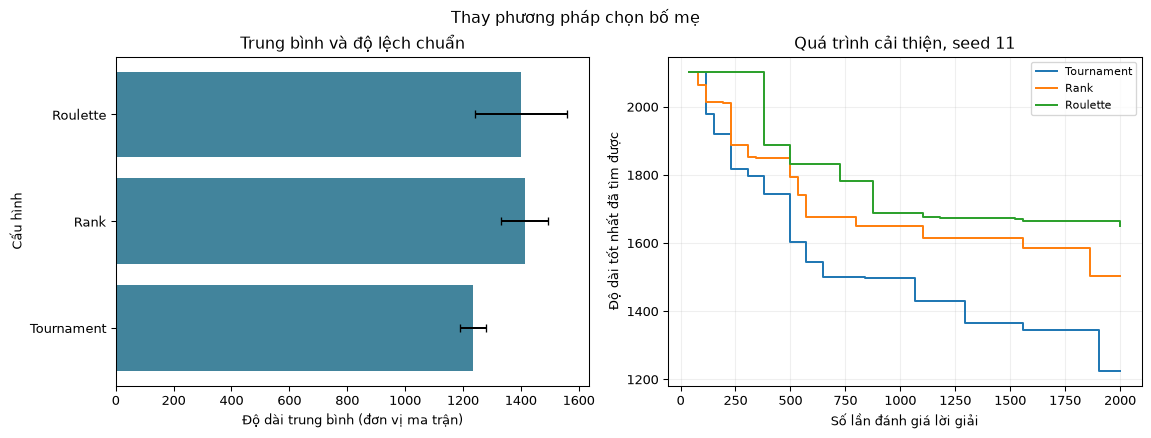

In [8]:
selection_runs = run_group(problem, configs)
selection_runs_summary = present_group(selection_runs, 'Thay phương pháp chọn bố mẹ')

In [9]:
discuss(selection_runs_summary, 'Các phương pháp nhận cùng giới hạn đánh giá; khác biệt quan sát được gắn với phương pháp chọn bố mẹ trong thiết kế này.')

**Nhận xét từ dữ liệu vừa chạy.** **Rank** có trung bình 1413.60, chênh +178.60 đơn vị so với **Tournament**; số đánh giá trung bình là 2000 thay vì 2000. **Roulette** có trung bình 1400.80, chênh +165.80 đơn vị so với **Tournament**; số đánh giá trung bình là 2000 thay vì 2000.

Trong nhóm này, Tournament có trung bình nhỏ nhất (1235.00). Các phương pháp nhận cùng giới hạn đánh giá; khác biệt quan sát được gắn với phương pháp chọn bố mẹ trong thiết kế này. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Trường hợp 3 - So sánh hai phép lai hợp lệ

**Partially Mapped Crossover, PMX (lai ghép ánh xạ một phần)** dùng ánh xạ giữa hai đoạn để giải quyết thành phố trùng. OX ưu tiên thứ tự đi qua thành phố; PMX bảo toàn đoạn tại các vị trí và dùng ánh xạ cho phần còn lại. Cả hai phải tạo hoán vị đầy đủ, giữ thành phố 0 ở đầu; notebook kiểm tra tour cuối của từng run.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [10]:
configs = {'OX': BASE, 'PMX': replace(BASE, crossover_method='pmx')}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| OX | 40 | 2000/2000 | 0.15 | 2000 |
| PMX | 40 | 2000/2000 | 0.15 | 2000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| OX | 1194 | 1235.00 | 43.86 | 2000–2000 | 51.0 | 0.0264 | MAX_EVALUATIONS: 5 |
| PMX | 1225 | 1275.40 | 38.34 | 2000–2000 | 51.0 | 0.0361 | MAX_EVALUATIONS: 5 |

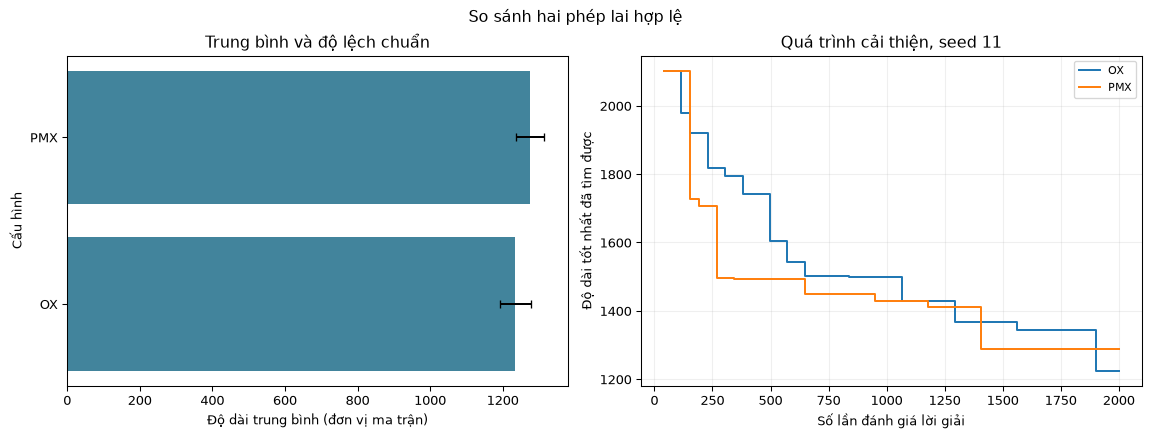

In [11]:
crossover_runs = run_group(problem, configs)
crossover_runs_summary = present_group(crossover_runs, 'So sánh hai phép lai hợp lệ')

In [12]:
discuss(crossover_runs_summary, 'Khác biệt về trung bình chưa cho phép khẳng định PMX hoặc OX luôn tốt hơn trên mọi ma trận.')

**Nhận xét từ dữ liệu vừa chạy.** **PMX** có trung bình 1275.40, chênh +40.40 đơn vị so với **OX**; số đánh giá trung bình là 2000 thay vì 2000.

Trong nhóm này, OX có trung bình nhỏ nhất (1235.00). Khác biệt về trung bình chưa cho phép khẳng định PMX hoặc OX luôn tốt hơn trên mọi ma trận. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Trường hợp 4 — So sánh cách đột biến tuyến đường

Bên cạnh Inversion, **Swap Mutation (hoán đổi)** đổi chỗ hai thành phố; **Insertion Mutation (chèn)** lấy một thành phố và đưa sang vị trí khác; **Scramble Mutation (xáo trộn đoạn)** đổi ngẫu nhiên thứ tự trong một đoạn. Mọi phương pháp giữ thành phố đầu và dùng cùng xác suất 15% trên cả tour, không phải 15% cho từng vị trí.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [13]:
configs = {name: replace(BASE, mutation_method=method) for name, method in
           [('Inversion', 'inversion'), ('Swap', 'swap'), ('Insertion', 'insertion'), ('Scramble', 'scramble')]}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Inversion | 40 | 2000/2000 | 0.15 | 2000 |
| Swap | 40 | 2000/2000 | 0.15 | 2000 |
| Insertion | 40 | 2000/2000 | 0.15 | 2000 |
| Scramble | 40 | 2000/2000 | 0.15 | 2000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Inversion | 1194 | 1235.00 | 43.86 | 2000–2000 | 51.0 | 0.0443 | MAX_EVALUATIONS: 5 |
| Swap | 1194 | 1317.00 | 113.40 | 2000–2000 | 51.0 | 0.0383 | MAX_EVALUATIONS: 5 |
| Insertion | 1263 | 1319.80 | 68.16 | 2000–2000 | 51.0 | 0.0397 | MAX_EVALUATIONS: 5 |
| Scramble | 1333 | 1473.00 | 152.78 | 2000–2000 | 51.0 | 0.0456 | MAX_EVALUATIONS: 5 |

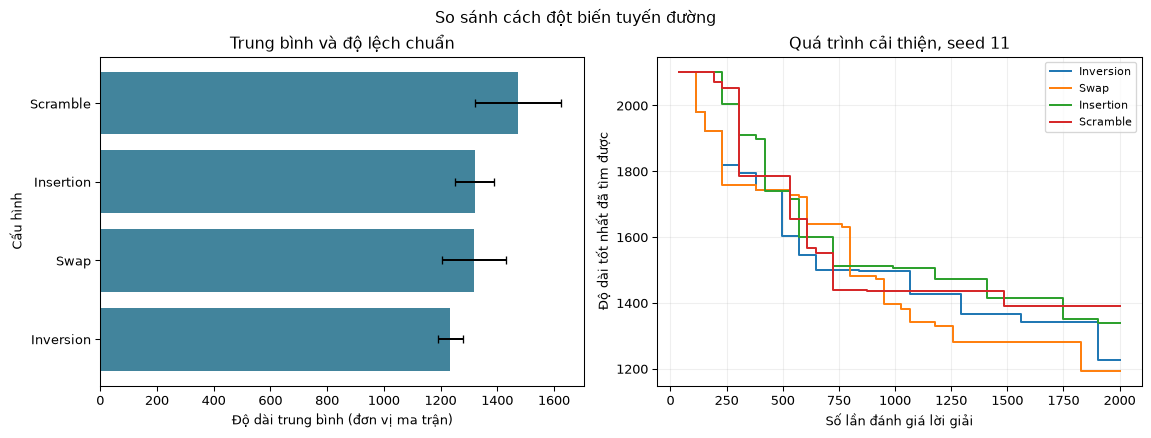

In [14]:
mutation_runs = run_group(problem, configs)
mutation_runs_summary = present_group(mutation_runs, 'So sánh cách đột biến tuyến đường')

In [15]:
discuss(mutation_runs_summary, 'Độ dài cuối và độ phân tán cần đọc cùng nhau; một run hội tụ nhanh không đại diện cho cả nhóm seed.')

**Nhận xét từ dữ liệu vừa chạy.** **Swap** có trung bình 1317.00, chênh +82.00 đơn vị so với **Inversion**; số đánh giá trung bình là 2000 thay vì 2000. **Insertion** có trung bình 1319.80, chênh +84.80 đơn vị so với **Inversion**; số đánh giá trung bình là 2000 thay vì 2000. **Scramble** có trung bình 1473.00, chênh +238.00 đơn vị so với **Inversion**; số đánh giá trung bình là 2000 thay vì 2000.

Trong nhóm này, Inversion có trung bình nhỏ nhất (1235.00). Độ dài cuối và độ phân tán cần đọc cùng nhau; một run hội tụ nhanh không đại diện cho cả nhóm seed. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Mức độ đa dạng và kết luận phần 1

Mức độ đa dạng mô tả số tuyến khác nhau còn lại trong quần thể. Code gộp hai tuyến chỉ khác chiều đi thành một chu trình vì ma trận đối xứng, rồi tính `(số tuyến khác nhau − 1)/(P − 1)`. Giá trị 0 nghĩa là chỉ còn một chu trình theo cách đếm này; giá trị 1 nghĩa là mọi cá thể khác nhau. Đây không phải tỷ lệ tìm được tối ưu. Hình sau dùng cùng seed đầu của ba phương pháp chọn bố mẹ; trục ngang vẫn là evaluations.

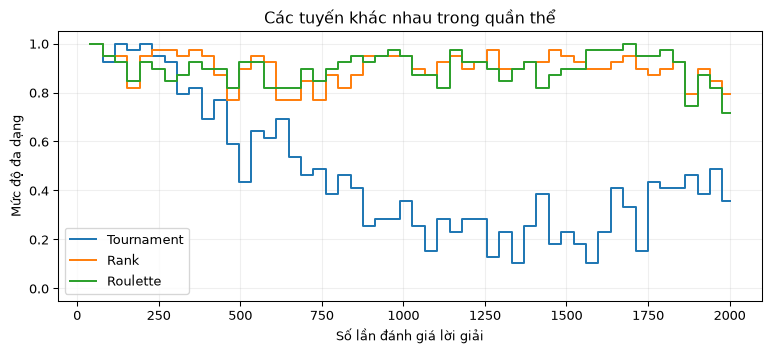

**Nhận xét.** Ở seed 11, đa dạng cuối của các phương pháp là Tournament: 0.359, Rank: 0.795, Roulette: 0.718. Trong các cấu hình đã khảo sát, Cơ bản có độ dài trung bình nhỏ nhất (1235.00). Độ đa dạng và chất lượng là hai thông tin khác nhau: nhiều tour khác nhau chưa chắc có tour ngắn hơn. Chúng tôi chỉ đổi từng toán tử, nên chưa khảo sát mọi cách kết hợp toán tử hoặc mọi bài toán.

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6), layout='constrained')
for name, runs in selection_runs.items():
    history = runs[0].history
    ax.step([s.evaluations for s in history], [s.population_diversity for s in history], where='post', label=name)
ax.set(xlabel='Số lần đánh giá lời giải', ylabel='Mức độ đa dạng', ylim=(-.05, 1.05), title='Các tuyến khác nhau trong quần thể')
ax.legend(); ax.grid(alpha=.2)
plt.show(); plt.close(fig)
operator_summary = {'Cơ bản': basic_runs_summary['Cơ bản'],
                    **{k:v for k,v in selection_runs_summary.items() if k != 'Tournament'},
                    'PMX': crossover_runs_summary['PMX'],
                    **{k:v for k,v in mutation_runs_summary.items() if k != 'Inversion'}}
best_operator_mean = min(v['mean'] for v in operator_summary.values())
best_operators = ', '.join(k for k,v in operator_summary.items() if v['mean'] == best_operator_mean)
last_diversity = ', '.join(f"{k}: {v[0].history[-1].population_diversity:.3f}" for k,v in selection_runs.items())
display(Markdown(f'**Nhận xét.** Ở seed {SEEDS[0]}, đa dạng cuối của các phương pháp là {last_diversity}. '
    f'Trong các cấu hình đã khảo sát, {best_operators} có độ dài trung bình nhỏ nhất ({best_operator_mean:.2f}). '
    'Độ đa dạng và chất lượng là hai thông tin khác nhau: nhiều tour khác nhau chưa chắc có tour ngắn hơn. '
    'Chúng tôi chỉ đổi từng toán tử, nên chưa khảo sát mọi cách kết hợp toán tử hoặc mọi bài toán.'))

## Phần 2. Tham số làm thay đổi chất lượng và khối lượng tính toán ra sao?

**Population Size (kích thước quần thể)** là số lời giải được duy trì. Quần thể lớn hơn có thể khảo sát nhiều tour hơn mỗi thế hệ nhưng phải tính thêm chi phí. **Generations (số thế hệ)** là số vòng tạo quần thể mới. **Mutation Rate (tỷ lệ đột biến)** quyết định cơ hội tạo biến đổi: quá ít biến đổi có thể hạn chế tìm kiếm, còn quá nhiều có thể làm thay đổi nhiều cấu trúc đang tốt; đây là giả thuyết cần kiểm chứng.

Chúng tôi giữ Tournament/OX/Inversion và hai cá thể tốt. Ba nhóm đầu thay một tham số; ba nhóm sau kết hợp hai tham số như notebook tham chiếu. QUICK dùng quần thể 20/40/80 và giới hạn 20/60/120 thế hệ; FULL dùng 40/80/160 và 100/150/500 thế hệ. Các mức này được chọn để máy sinh viên chạy hữu hạn, không khẳng định là tham số tối ưu.

Có hai câu hỏi khác nhau: cùng số thế hệ thì tăng P ảnh hưởng thế nào, và cùng số evaluations thì phân bổ cho P khác nhau có hiệu quả ra sao? Chúng tôi tách chúng thành hai nhóm, không trộn kết luận. Giới hạn an toàn 20000 evaluations ở QUICK hoặc 100000 ở FULL đủ cho mọi cấu hình khảo sát theo thế hệ; bảng trạng thái giúp phát hiện nếu một run dừng sớm vì lý do khác.

In [17]:
P_LOW, P_MID, P_HIGH = (20, 40, 80) if MODE == 'QUICK' else (40, 80, 160)
G_LOW, G_MID, G_HIGH = (20, 60, 120) if MODE == 'QUICK' else (100, 150, 500)
SAFETY_EVALUATIONS = 20000 if MODE == 'QUICK' else 100000
PARAM_BASE = replace(GAConfig(), population_size=P_MID, generations=G_MID,
                     max_iterations=G_MID, max_evaluations=SAFETY_EVALUATIONS, time_limit_seconds=10.0)

### Thí nghiệm 1a — Kích thước quần thể, cùng số thế hệ

Giữ cùng số thế hệ để quan sát P. Nhiều cá thể hơn đồng nghĩa nhiều evaluations hơn; nếu chất lượng cải thiện thì không quy toàn bộ lợi ích cho P mà bỏ qua lượng tính toán tăng.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [18]:
configs = {f'P={p}': replace(PARAM_BASE, population_size=p) for p in [P_LOW, P_MID, P_HIGH]}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| P=20 | 20 | 60/60 | 0.15 | 20000 |
| P=40 | 40 | 60/60 | 0.15 | 20000 |
| P=80 | 80 | 60/60 | 0.15 | 20000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| P=20 | 1225 | 1326.00 | 85.99 | 1100–1100 | 60.0 | 0.0271 | MAX_ITERATIONS: 5 |
| P=40 | 1194 | 1227.60 | 36.95 | 2320–2320 | 60.0 | 0.0585 | MAX_ITERATIONS: 5 |
| P=80 | 1194 | 1200.20 | 13.86 | 4760–4760 | 60.0 | 0.1142 | MAX_ITERATIONS: 5 |

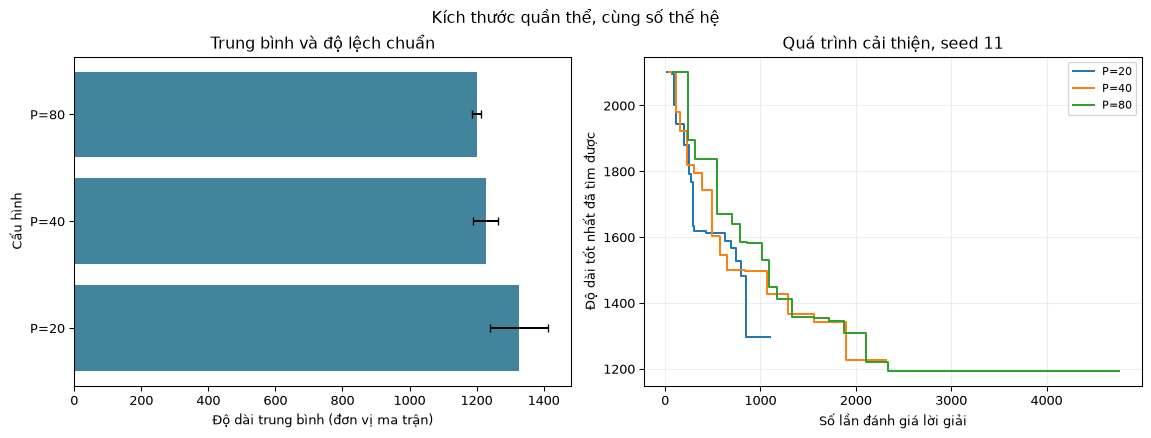

In [19]:
population_runs = run_group(problem, configs)
population_runs_summary = present_group(population_runs, 'Kích thước quần thể, cùng số thế hệ')

In [20]:
discuss(population_runs_summary, 'Nhóm này giữ số thế hệ, không giữ số phép đánh giá; cần đọc cột thời gian và evaluations trước khi chọn P.')

**Nhận xét từ dữ liệu vừa chạy.** **P=40** có trung bình 1227.60, chênh -98.40 đơn vị so với **P=20**; số đánh giá trung bình là 2320 thay vì 1100. **P=80** có trung bình 1200.20, chênh -125.80 đơn vị so với **P=20**; số đánh giá trung bình là 4760 thay vì 1100.

Trong nhóm này, P=80 có trung bình nhỏ nhất (1200.20). Nhóm này giữ số thế hệ, không giữ số phép đánh giá; cần đọc cột thời gian và evaluations trước khi chọn P. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Thí nghiệm 1b — Kích thước quần thể, cùng số evaluations

Lần này đặt cùng giới hạn đánh giá và nới cả hai giới hạn thế hệ. P nhỏ có thể hoàn tất nhiều thế hệ hơn. Nhóm này trả lời câu hỏi sử dụng cùng số phép đánh giá, khác với nhóm 1a.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [21]:
configs = {f'P={p}': replace(BASE, population_size=p) for p in [P_LOW, P_MID, P_HIGH]}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| P=20 | 20 | 2000/2000 | 0.15 | 2000 |
| P=40 | 40 | 2000/2000 | 0.15 | 2000 |
| P=80 | 80 | 2000/2000 | 0.15 | 2000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| P=20 | 1194 | 1270.80 | 71.71 | 2000–2000 | 110.0 | 0.0495 | MAX_EVALUATIONS: 5 |
| P=40 | 1194 | 1235.00 | 43.86 | 2000–2000 | 51.0 | 0.0449 | MAX_EVALUATIONS: 5 |
| P=80 | 1240 | 1296.40 | 45.15 | 2000–2000 | 24.0 | 0.0505 | MAX_EVALUATIONS: 5 |

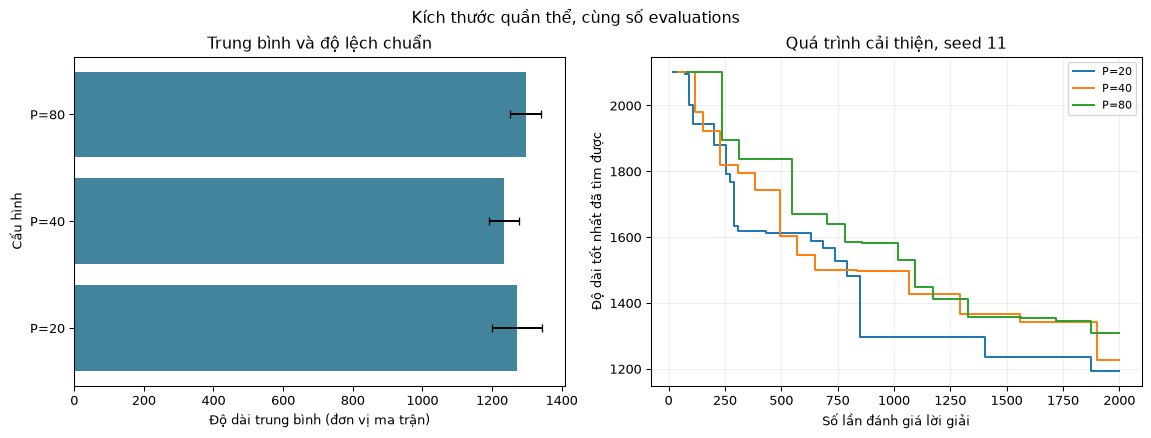

In [22]:
population_equal_runs = run_group(problem, configs)
population_equal_runs_summary = present_group(population_equal_runs, 'Kích thước quần thể, cùng số evaluations')

In [23]:
discuss(population_equal_runs_summary, 'Cùng số evaluations vẫn chưa có nghĩa cùng thời gian vì chi phí chọn lọc, tạo con và quản lý quần thể có thể khác.')

**Nhận xét từ dữ liệu vừa chạy.** **P=40** có trung bình 1235.00, chênh -35.80 đơn vị so với **P=20**; số đánh giá trung bình là 2000 thay vì 2000. **P=80** có trung bình 1296.40, chênh +25.60 đơn vị so với **P=20**; số đánh giá trung bình là 2000 thay vì 2000.

Trong nhóm này, P=40 có trung bình nhỏ nhất (1235.00). Cùng số evaluations vẫn chưa có nghĩa cùng thời gian vì chi phí chọn lọc, tạo con và quản lý quần thể có thể khác. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Thí nghiệm 2 — Tỷ lệ đột biến

Thử 1%,15% và 50%, giữ nguyên P và số thế hệ. Chúng tôi muốn xem cả tỷ lệ thấp lẫn cao trong cùng điều kiện, thay vì giả định tỷ lệ càng cao càng tốt.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [24]:
configs = {f'Đột biến {rate:.0%}': replace(PARAM_BASE, mutation_rate=rate) for rate in [.01, .15, .50]}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Đột biến 1% | 40 | 60/60 | 0.01 | 20000 |
| Đột biến 15% | 40 | 60/60 | 0.15 | 20000 |
| Đột biến 50% | 40 | 60/60 | 0.5 | 20000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Đột biến 1% | 1257 | 1593.60 | 267.93 | 2320–2320 | 60.0 | 0.0618 | MAX_ITERATIONS: 5 |
| Đột biến 15% | 1194 | 1227.60 | 36.95 | 2320–2320 | 60.0 | 0.0546 | MAX_ITERATIONS: 5 |
| Đột biến 50% | 1194 | 1233.80 | 43.00 | 2320–2320 | 60.0 | 0.0624 | MAX_ITERATIONS: 5 |

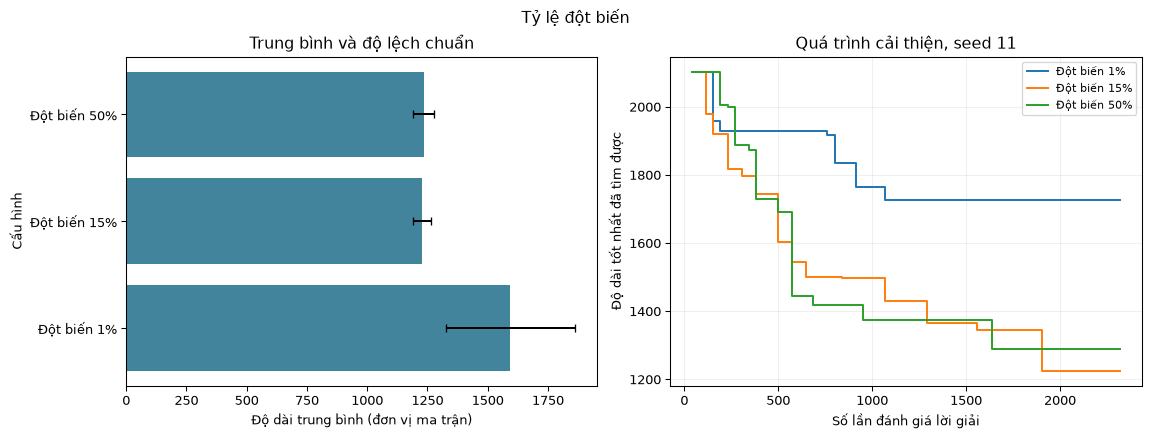

In [25]:
rate_runs = run_group(problem, configs)
rate_runs_summary = present_group(rate_runs, 'Tỷ lệ đột biến')

In [26]:
discuss(rate_runs_summary, 'Không suy ra một tỷ lệ tối ưu phổ quát từ ba giá trị thử; đây chỉ là quan sát trên bài15 thành phố.')

**Nhận xét từ dữ liệu vừa chạy.** **Đột biến 15%** có trung bình 1227.60, chênh -366.00 đơn vị so với **Đột biến 1%**; số đánh giá trung bình là 2320 thay vì 2320. **Đột biến 50%** có trung bình 1233.80, chênh -359.80 đơn vị so với **Đột biến 1%**; số đánh giá trung bình là 2320 thay vì 2320.

Trong nhóm này, Đột biến 15% có trung bình nhỏ nhất (1227.60). Không suy ra một tỷ lệ tối ưu phổ quát từ ba giá trị thử; đây chỉ là quan sát trên bài15 thành phố. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Thí nghiệm 3 — Số thế hệ

Đặt generations và max_iterations bằng nhau ở từng mức. Giới hạn evaluations đủ lớn cho mức thế hệ cao nhất; nhờ vậy tăng generations thực sự cho phép chạy thêm vòng, trừ trường hợp chạm thời gian được ghi trong bảng.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [27]:
configs = {f'G={g}': replace(PARAM_BASE, generations=g, max_iterations=g) for g in [G_LOW, G_MID, G_HIGH]}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| G=20 | 40 | 20/20 | 0.15 | 20000 |
| G=60 | 40 | 60/60 | 0.15 | 20000 |
| G=120 | 40 | 120/120 | 0.15 | 20000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| G=20 | 1387 | 1476.00 | 54.82 | 800–800 | 20.0 | 0.0206 | MAX_ITERATIONS: 5 |
| G=60 | 1194 | 1227.60 | 36.95 | 2320–2320 | 60.0 | 0.0601 | MAX_ITERATIONS: 5 |
| G=120 | 1194 | 1200.20 | 13.86 | 4600–4600 | 120.0 | 0.0960 | MAX_ITERATIONS: 5 |

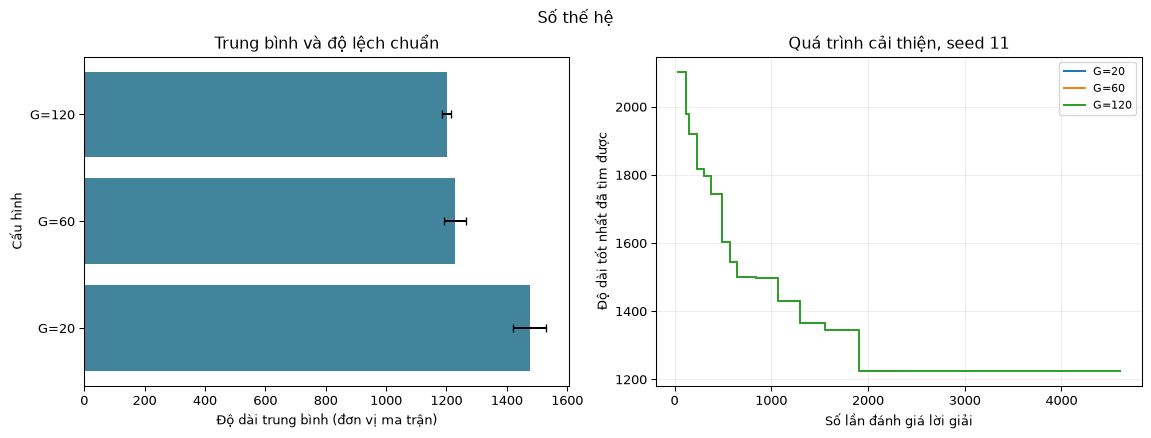

In [28]:
generation_runs = run_group(problem, configs)
generation_runs_summary = present_group(generation_runs, 'Số thế hệ')

In [29]:
discuss(generation_runs_summary, 'Chạy nhiều thế hệ sử dụng thêm phép tính; nếu đường ít cải thiện về cuối thì chỉ là hiện tượng của mẫu này, không phải bằng chứng đã đạt tối ưu.')

**Nhận xét từ dữ liệu vừa chạy.** **G=60** có trung bình 1227.60, chênh -248.40 đơn vị so với **G=20**; số đánh giá trung bình là 2320 thay vì 800. **G=120** có trung bình 1200.20, chênh -275.80 đơn vị so với **G=20**; số đánh giá trung bình là 4600 thay vì 800.

Trong nhóm này, G=120 có trung bình nhỏ nhất (1200.20). Chạy nhiều thế hệ sử dụng thêm phép tính; nếu đường ít cải thiện về cuối thì chỉ là hiện tượng của mẫu này, không phải bằng chứng đã đạt tối ưu. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Thí nghiệm 4 — Kết hợp kích thước quần thể và tỷ lệ đột biến

Thử một bảng nhỏ 2×2 gồm P thấp/cao và xác suất 5%/30%, giữ nguyên số thế hệ. Đổi đồng thời hai yếu tố giúp nhìn tương tác nhưng không tách được nguyên nhân chỉ từ một cặp kết quả.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [30]:
configs = {f'P={p}, đột biến {rate:.0%}': replace(PARAM_BASE, population_size=p, mutation_rate=rate)
           for p in [P_LOW, P_HIGH] for rate in [.05, .30]}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| P=20, đột biến 5% | 20 | 60/60 | 0.05 | 20000 |
| P=20, đột biến 30% | 20 | 60/60 | 0.3 | 20000 |
| P=80, đột biến 5% | 80 | 60/60 | 0.05 | 20000 |
| P=80, đột biến 30% | 80 | 60/60 | 0.3 | 20000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| P=20, đột biến 5% | 1420 | 1523.40 | 71.85 | 1100–1100 | 60.0 | 0.0217 | MAX_ITERATIONS: 5 |
| P=20, đột biến 30% | 1194 | 1316.80 | 84.67 | 1100–1100 | 60.0 | 0.0200 | MAX_ITERATIONS: 5 |
| P=80, đột biến 5% | 1194 | 1287.40 | 106.73 | 4760–4760 | 60.0 | 0.0829 | MAX_ITERATIONS: 5 |
| P=80, đột biến 30% | 1194 | 1200.20 | 13.86 | 4760–4760 | 60.0 | 0.1076 | MAX_ITERATIONS: 5 |

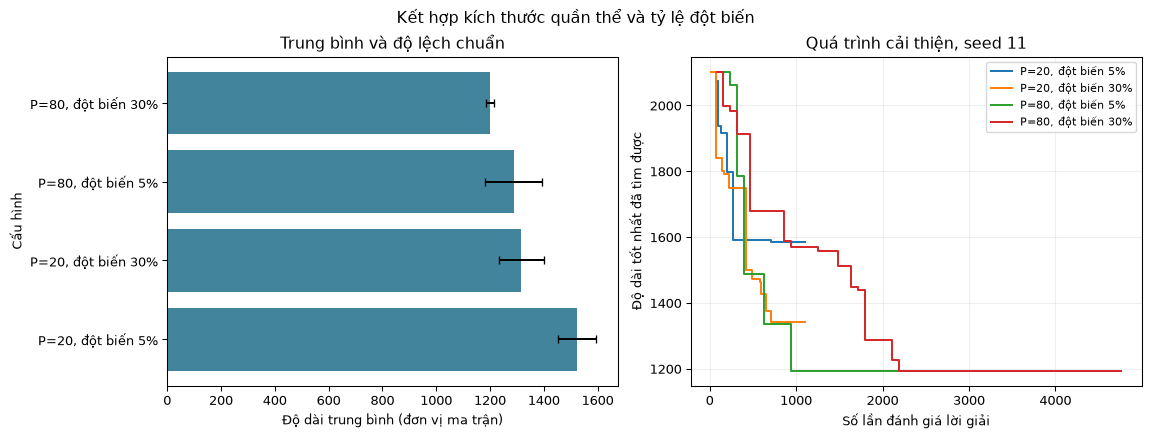

In [31]:
population_rate_runs = run_group(problem, configs)
population_rate_runs_summary = present_group(population_rate_runs, 'Kết hợp kích thước quần thể và tỷ lệ đột biến')

In [32]:
discuss(population_rate_runs_summary, 'Vì số cá thể và tỷ lệ biến đổi cùng thay đổi, kết quả không chứng minh riêng một yếu tố gây ra mọi khác biệt.')

**Nhận xét từ dữ liệu vừa chạy.** **P=20, đột biến 30%** có trung bình 1316.80, chênh -206.60 đơn vị so với **P=20, đột biến 5%**; số đánh giá trung bình là 1100 thay vì 1100. **P=80, đột biến 5%** có trung bình 1287.40, chênh -236.00 đơn vị so với **P=20, đột biến 5%**; số đánh giá trung bình là 4760 thay vì 1100. **P=80, đột biến 30%** có trung bình 1200.20, chênh -323.20 đơn vị so với **P=20, đột biến 5%**; số đánh giá trung bình là 4760 thay vì 1100.

Trong nhóm này, P=80, đột biến 30% có trung bình nhỏ nhất (1200.20). Vì số cá thể và tỷ lệ biến đổi cùng thay đổi, kết quả không chứng minh riêng một yếu tố gây ra mọi khác biệt. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Thí nghiệm 5 — Kết hợp tỷ lệ đột biến và số thế hệ

Giữ P ở mức giữa, phối hợp hai tỷ lệ 5%/30% với số thế hệ thấp/cao. Đọc các cặp cùng tỷ lệ để xem tác động của chạy thêm vòng, rồi đọc các cặp cùng G để đối chiếu xác suất.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [33]:
configs = {f'G={g}, đột biến {rate:.0%}': replace(PARAM_BASE, generations=g, max_iterations=g, mutation_rate=rate)
           for g in [G_LOW, G_HIGH] for rate in [.05, .30]}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| G=20, đột biến 5% | 40 | 20/20 | 0.05 | 20000 |
| G=20, đột biến 30% | 40 | 20/20 | 0.3 | 20000 |
| G=120, đột biến 5% | 40 | 120/120 | 0.05 | 20000 |
| G=120, đột biến 30% | 40 | 120/120 | 0.3 | 20000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| G=20, đột biến 5% | 1437 | 1556.80 | 112.33 | 800–800 | 20.0 | 0.0141 | MAX_ITERATIONS: 5 |
| G=20, đột biến 30% | 1383 | 1519.40 | 117.26 | 800–800 | 20.0 | 0.0146 | MAX_ITERATIONS: 5 |
| G=120, đột biến 5% | 1194 | 1244.20 | 50.97 | 4600–4600 | 120.0 | 0.0888 | MAX_ITERATIONS: 5 |
| G=120, đột biến 30% | 1194 | 1282.80 | 72.66 | 4600–4600 | 120.0 | 0.0971 | MAX_ITERATIONS: 5 |

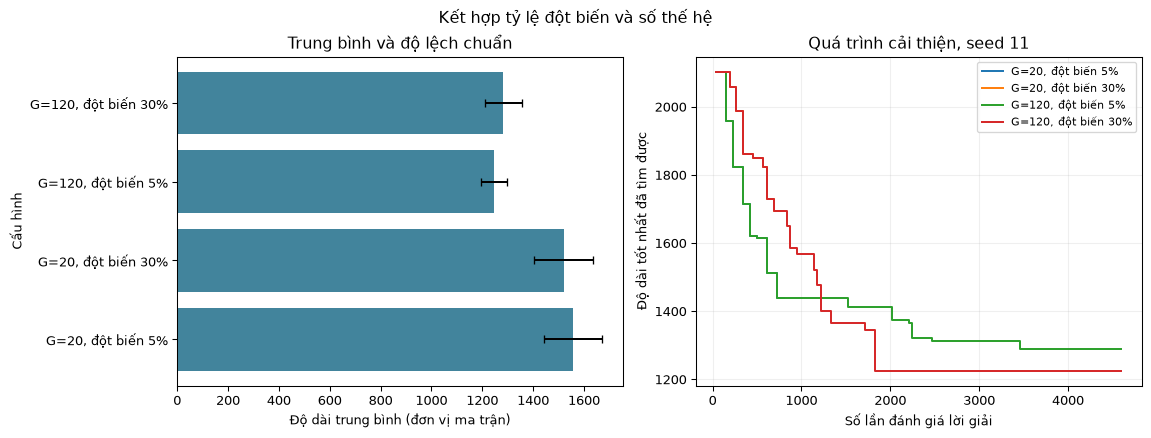

In [34]:
rate_generation_runs = run_group(problem, configs)
rate_generation_runs_summary = present_group(rate_generation_runs, 'Kết hợp tỷ lệ đột biến và số thế hệ')

In [35]:
discuss(rate_generation_runs_summary, 'Những cấu hình chạy lâu hơn dùng thêm evaluations; không gọi đây là so sánh cùng nguồn lực tính toán.')

**Nhận xét từ dữ liệu vừa chạy.** **G=20, đột biến 30%** có trung bình 1519.40, chênh -37.40 đơn vị so với **G=20, đột biến 5%**; số đánh giá trung bình là 800 thay vì 800. **G=120, đột biến 5%** có trung bình 1244.20, chênh -312.60 đơn vị so với **G=20, đột biến 5%**; số đánh giá trung bình là 4600 thay vì 800. **G=120, đột biến 30%** có trung bình 1282.80, chênh -274.00 đơn vị so với **G=20, đột biến 5%**; số đánh giá trung bình là 4600 thay vì 800.

Trong nhóm này, G=120, đột biến 5% có trung bình nhỏ nhất (1244.20). Những cấu hình chạy lâu hơn dùng thêm evaluations; không gọi đây là so sánh cùng nguồn lực tính toán. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Thí nghiệm 6 — Kết hợp số thế hệ và kích thước quần thể

Giữ tỷ lệ 15% và dùng bảng nhỏ 2×2 giữa P thấp/cao và G thấp/cao. Lượng đánh giá tăng theo cả P và G, nên chúng tôi giữ số thực chạy và thời gian bên cạnh chất lượng để tránh chỉ chọn tour ngắn nhất.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [36]:
configs = {f'P={p}, G={g}': replace(PARAM_BASE, population_size=p, generations=g, max_iterations=g)
           for p in [P_LOW, P_HIGH] for g in [G_LOW, G_HIGH]}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| P=20, G=20 | 20 | 20/20 | 0.15 | 20000 |
| P=20, G=120 | 20 | 120/120 | 0.15 | 20000 |
| P=80, G=20 | 80 | 20/20 | 0.15 | 20000 |
| P=80, G=120 | 80 | 120/120 | 0.15 | 20000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| P=20, G=20 | 1336 | 1568.80 | 178.94 | 380–380 | 20.0 | 0.0086 | MAX_ITERATIONS: 5 |
| P=20, G=120 | 1194 | 1247.60 | 61.33 | 2180–2180 | 120.0 | 0.0441 | MAX_ITERATIONS: 5 |
| P=80, G=20 | 1308 | 1400.60 | 76.36 | 1640–1640 | 20.0 | 0.0302 | MAX_ITERATIONS: 5 |
| P=80, G=120 | 1194 | 1200.20 | 13.86 | 9440–9440 | 120.0 | 0.1798 | MAX_ITERATIONS: 5 |

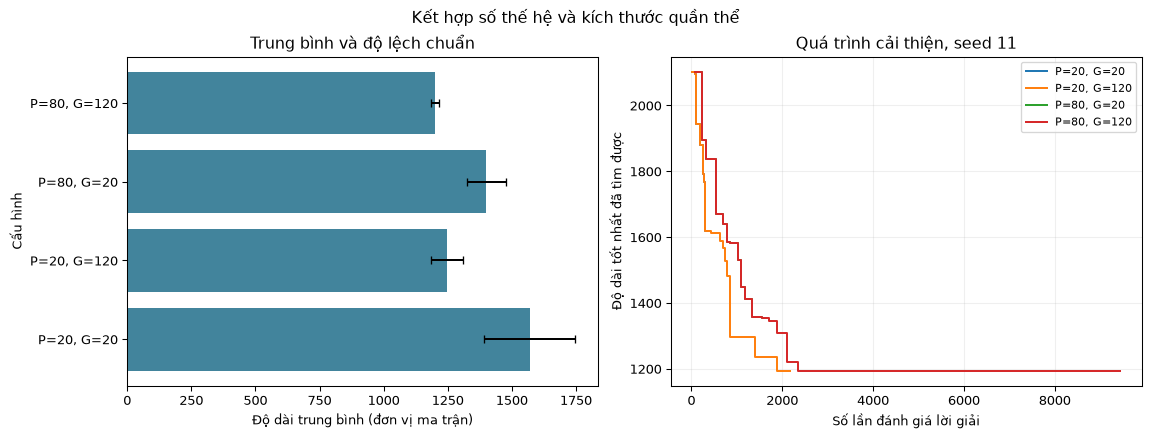

In [37]:
generation_population_runs = run_group(problem, configs)
generation_population_runs_summary = present_group(generation_population_runs, 'Kết hợp số thế hệ và kích thước quần thể')

In [38]:
discuss(generation_population_runs_summary, 'Tăng đồng thời hai tham số là quyết định dùng thêm tính toán, không phải một cải tiến miễn phí.')

**Nhận xét từ dữ liệu vừa chạy.** **P=20, G=120** có trung bình 1247.60, chênh -321.20 đơn vị so với **P=20, G=20**; số đánh giá trung bình là 2180 thay vì 380. **P=80, G=20** có trung bình 1400.60, chênh -168.20 đơn vị so với **P=20, G=20**; số đánh giá trung bình là 1640 thay vì 380. **P=80, G=120** có trung bình 1200.20, chênh -368.60 đơn vị so với **P=20, G=20**; số đánh giá trung bình là 9440 thay vì 380.

Trong nhóm này, P=80, G=120 có trung bình nhỏ nhất (1200.20). Tăng đồng thời hai tham số là quyết định dùng thêm tính toán, không phải một cải tiến miễn phí. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

### Kết luận Experiment 1–2

Đoạn dưới kết nối kết quả toán tử với ba tham số chính. Các tên và số liệu được tạo từ bảng vừa tính, nên sẽ cập nhật nếu đổi seed hoặc chế độ.

In [39]:
best_population = min(population_equal_runs_summary, key=lambda k: population_equal_runs_summary[k]['mean'])
best_rate = min(rate_runs_summary, key=lambda k: rate_runs_summary[k]['mean'])
generation_names = list(generation_runs_summary)
first, last = (generation_runs_summary[generation_names[i]] for i in [0, -1])
display(Markdown(f'Trong phần toán tử, {best_operators} đạt trung bình nhỏ nhất ({best_operator_mean:.2f}). '
    f'Khi giữ cùng evaluations, cấu hình {best_population} có trung bình nhỏ nhất trong các mức P đã thử; '
    f'trong nhóm tỷ lệ đột biến, {best_rate} đứng đầu theo trung bình. '
    f'Khi tăng từ {G_LOW} lên {G_HIGH} thế hệ, độ dài trung bình đổi từ {first["mean"]:.2f} '
    f'thành {last["mean"]:.2f}, còn evaluations trung bình đổi từ {first["eval_mean"]:.0f} '
    f'thành {last["eval_mean"]:.0f}. '
    'Selection, Crossover và Mutation quyết định cách tạo và chọn lời giải; P, G và tỷ lệ đột biến điều chỉnh '
    'mức khảo sát của quá trình đó. Các nhóm kết hợp cho thấy cần đọc chất lượng cùng chi phí tính toán. '
    'Kết quả chỉ mô tả những mức đã thử trên một ma trận, không chứng minh có một bộ tham số luôn tốt nhất.'))
repro_problem, repro_result = problem, crossover_runs['PMX'][0]

Trong phần toán tử, Cơ bản đạt trung bình nhỏ nhất (1235.00). Khi giữ cùng evaluations, cấu hình P=40 có trung bình nhỏ nhất trong các mức P đã thử; trong nhóm tỷ lệ đột biến, Đột biến 15% đứng đầu theo trung bình. Khi tăng từ 20 lên 120 thế hệ, độ dài trung bình đổi từ 1476.00 thành 1200.20, còn evaluations trung bình đổi từ 800 thành 4600. Selection, Crossover và Mutation quyết định cách tạo và chọn lời giải; P, G và tỷ lệ đột biến điều chỉnh mức khảo sát của quá trình đó. Các nhóm kết hợp cho thấy cần đọc chất lượng cùng chi phí tính toán. Kết quả chỉ mô tả những mức đã thử trên một ma trận, không chứng minh có một bộ tham số luôn tốt nhất.

## Kiểm tra tái lập và tổng kết lần chạy

Chúng tôi chạy lại đúng cấu hình và seed của một kết quả đã có. Tour, độ dài, số lần đánh giá và toàn bộ lịch sử số phải khớp; thời gian được loại khỏi phép so sánh vì phụ thuộc môi trường. Lần kiểm tra này được đếm riêng, không đưa thêm vào thống kê nhiều seed.

In [40]:
repeat = checked_solve(repro_problem, GAConfig(**repro_result.config_snapshot))
assert numeric_signature(repeat) == numeric_signature(repro_result)
expected_main_runs = 34 * len(SEEDS)
assert RUN_COUNT == expected_main_runs + 1
NOTEBOOK_REPORT = dict(notebook='Experiment 1-2', mode=MODE, seeds=SEEDS,
                       experiment_runs=expected_main_runs, verification_runs=1,
                       total_runs=RUN_COUNT, solver_seconds=SOLVER_SECONDS,
                       wall_seconds=perf_counter() - SESSION_START,
                       summaries=dict(operators=operator_summary, population=population_runs_summary, population_equal=population_equal_runs_summary, mutation_rate=rate_runs_summary, generations=generation_runs_summary, population_rate=population_rate_runs_summary, rate_generation=rate_generation_runs_summary, generation_population=generation_population_runs_summary))
display(Markdown(f"Đã hoàn tất **{expected_main_runs} lần thực nghiệm** và **1 lần kiểm tra tái lập**, "
    f"tổng {RUN_COUNT} lần gọi GA. Thời gian trong solver là {SOLVER_SECONDS:.3f} giây. "
    'Mọi tour đã qua kiểm tra chi phí và hoán vị; không có lần lỗi nào bị bỏ khỏi thống kê. '
    'Các kết quả khi dừng sớm vẫn được giữ cùng lý do dừng trong bảng.'))

Đã hoàn tất **170 lần thực nghiệm** và **1 lần kiểm tra tái lập**, tổng 171 lần gọi GA. Thời gian trong solver là 8.713 giây. Mọi tour đã qua kiểm tra chi phí và hoán vị; không có lần lỗi nào bị bỏ khỏi thống kê. Các kết quả khi dừng sớm vẫn được giữ cùng lý do dừng trong bảng.